- title: Занятие 5
- author: Ivan Alexandrovich Stepanov
- date: 2024-10-03
- slug: 2024_bio_lab05
- ipynb_url: download/2024_bio_lab05.ipynb- lecture_link: 2024/2024_bio_lec05.html
- lecture_comment: Конспект лекции №5

# Лабораторная работа 5

***NumPy***(сокращенно от Numerical Python)— библиотека с открытым исходным кодом для языка программирования Python.

* поддержмвает многомерные массивы (включая матрицы)
* поддерживает высокоуровневые математические функции, предназначенные для работы с многомерными массивами.

NumPy обеспечивает как гибкость Python, так и скорость хорошо оптимизированного скомпилированного кода на C. 

Если у вас ещё не установлен Numpy это можно сделать командой: 
```bash
pip install numpy
```

##  0. Массивы в Numpy 

* Массив в NumPy это таблица элементов одного типа, пронумерованная кортежем положительных целых чисел.
* В NumPy измерения называются осями. Количество осей является рангом.
* Класс массива NumPy называется ndarray.

Обратите внимание, что массив в Numpy содержит элементы одного типа, в отличие от списка!

In [3]:
import numpy as np  # импортируем библиотеку и заменим её ключевым словом np(для удобства)

In [4]:
arr1 = np.array([1, 2, 3])  # массив ранга 1
arr2 = np.array( [[1, 2, 3], [4, 2, 5]] )  # массив ранга 2(матрица с двумя строками и тремя столбцами)

## 1. Создание массива

Есть несколько способов создать массив NumPy. Рассмотрим их подробнее:   

### 1.1 Функция array

Вы можете создать массив из обычного списка или кортежа, используя array().

In [5]:
a = np.array([[1, 2, 3], [4, 5, 6]], dtype = 'int')
print(a)

[[1 2 3]
 [4 5 6]]


### 1.2. Создание массива c заполнением начальными значениями

Допустим нам неизвестны элементы массива, но известен его размер. В NumPy существуют функции для создания массивов с начальным заполнением. 

In [6]:
a = np.zeros(5)  # создаём 1-d массив, содержащий 5 нулей
print('a:', a)
b = np.ones(5)  # создаём 1-d массив, содержащий 5 единиц
print('b:', b)

a: [0. 0. 0. 0. 0.]
b: [1. 1. 1. 1. 1.]


Обратите внимание, что по-умолчанию тип чисел дробный. Но можно явно указать целый тип `int`:

In [7]:
a = np.zeros(5, dtype='int')  # создаём 1-d массив, содержащий 5 нулей
print('a:', a)
b = np.ones(5, dtype='int')  # создаём 1-d массив, содержащий 5 единиц
print('b:', b)

a: [0 0 0 0 0]
b: [1 1 1 1 1]


In [8]:
c = np.zeros((3, 5))  # создаём 2-d массив, размера 3 на 5
print(c)

[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


In [9]:
r = np.random.random(5)  # создаём массив со случайными значениями на определённом интервале
print('r:', r)

r: [0.13501954 0.41625599 0.58906219 0.25328585 0.56087161]


### 1.3. Фунция arange

In [10]:
a = np.arange(0, 10, 2) # создаём массив от 0 до 10 с шагом 2
print(a)

[0 2 4 6 8]


### 1.4. reshape

Размеры массива содержатся в атрибуте `a.shape`.
Поскольку массивы NumPy многомерный — это кортеж.

In [11]:
a = np.array([[1, 2, 3, 4], [5, 2, 4, 2]])
print('a: ', a.shape)

a:  (2, 4)


Мы также можем менять размеры массивов.

In [12]:
new_a = a.reshape(4, 2)
print('new_a: ', new_a.shape)

new_a:  (4, 2)


### 1.5. flatten

Любой многомерный массив мы можем развернуть с помощью функции flatten.

In [13]:
a = np.array([[1, 2, 3, 4], [5, 2, 4, 2]])
new_a = a.flatten()
print(new_a)

[1 2 3 4 5 2 4 2]


## 2. Идексация массивов

### 2.1 Одномерных

In [14]:
a = np.arange(10) # создадим массив
print(a)

[0 1 2 3 4 5 6 7 8 9]


In [15]:
# как можно заменить доступ остался таким же как в списках
print('четвёртый элемент:', a[3])
print('последний элемент:', a[-1])
a[3] = 11
print('теперь четвёртый элемент:', a[3])

четвёртый элемент: 3
последний элемент: 9
теперь четвёртый элемент: 11


In [16]:
# мы также можем создавать срезы, как и в списках.
new_a = a[1:5]

In [17]:
# теперь немного магии
new_a[1] = -10
print(a)

[  0   1 -10  11   4   5   6   7   8   9]


Мы поменяли элемент среза и наш исходный массив тоже изменился!!! Почему?  Это сделано специально для экономии памяти. Данные на которые ссылаются ***a*** и ***new_a*** одни и те же. Срезы – это не полноценные копии массивов, а скорее их новое представление.

### 2.2 Многомерных

In [18]:
x = np.array([(1, 2, 3), (4, 5, 6), (7, 8, 9)]) # создаём многомерный массив

С точки зрения математики, можно сказать, что нашим объектом является следующая матрица. 

\begin{equation}
  \begin{bmatrix}
    1 & 2 & 3\\
    4 & 5 & 6\\
    7 & 8 & 9
  \end{bmatrix}
  \label{eq:aeqn}
\end{equation}

In [19]:
#мы также можем обращаться к элементам матрицы следующим образом
print(x[2][2])
# можем обратиться только к конкретной строке 
print(x[0])
# к конкретному столбцу
print(x[:,0])

9
[1 2 3]
[1 4 7]


Итерирование многомерных массивов можно выполнять с помощью вложенных циклов. 

In [20]:
for row in x:
    for value in row:
        print(value, end=' ')
    print()

1 2 3 
4 5 6 
7 8 9 


Можно использовать flat, позволяющий выводить элементы многомерного массива поэлемента. 

In [21]:
for val in x.flat:
    print(val, end=' ')

1 2 3 4 5 6 7 8 9 

## 3. Операции над массивами

### 3.1 Математические операции

In [22]:
# создадим два массива
a = np.array([(1, 2, 3), (4, 5, 6), (7, 8, 9)])
b = np.array([(19, 20, 21), (22, 23, 24), (25, 26, 27)])

Мы можем складывать, умножать, делить, считать остаток и т.д поэлементно.

In [23]:
# сумма
print(a + b)

[[20 22 24]
 [26 28 30]
 [32 34 36]]


In [24]:
# разность
print(a - b)

[[-18 -18 -18]
 [-18 -18 -18]
 [-18 -18 -18]]


In [25]:
# умножение
print(a * b)

[[ 19  40  63]
 [ 88 115 144]
 [175 208 243]]


In [26]:
# остаток от деления
print(b % a)

[[0 0 0]
 [2 3 0]
 [4 2 0]]


In [27]:
# Также, в numpy есть библиотека стандартных мат функций, которые можно применить к каждому элементу массива. 
a = np.array([(1, 2, 3), (4, 5, 6), (7, 8, 9)])
np.sqrt(a)

array([[1.        , 1.41421356, 1.73205081],
       [2.        , 2.23606798, 2.44948974],
       [2.64575131, 2.82842712, 3.        ]])

### 3.2 Базовые операции с массивыми

In [28]:
a = np.array([(1, 2, 3, 4, 5, 6, 7, 8, 9)])
# сумма элементов
print(a.sum())
# произведение элементов
print(a.prod())
# макс и мин элемент
print(a.max())
print(a.min())
# среднее значение
print(a.mean())
# дисперсия
print(a.var())

45
362880
9
1
5.0
6.666666666666667


***P.S NumPy - мощный интсрумент, который содержит в себе много функций и методов.*** 

Обращайтесь к туториалу: https://numpy.org/devdocs/user/quickstart.html

И не бойтесь гуглить!

### Задача 1

Создайте две numpy матрицы, содержащие температуры в Кельвинах и Фаренгейтах на основе матрицы температур в Цельсиях.

In [29]:
a = np.array([(14, 23, 31, 14, 55, 36, 87, 118, 91)]) # матрица температур(в Цельсиях)

In [36]:
c = a * 1.8 + 32
b = a - 273
print(c, b)

[[ 57.2  73.4  87.8  57.2 131.   96.8 188.6 244.4 195.8]] [[-259 -250 -242 -259 -218 -237 -186 -155 -182]]


### 3.3 Умножения матриц

In [34]:
a = np.array([(1, 2, 3), (4, 5, 6), (7, 8, 9)])
a = np.array([(1), (4), (7)])
# можем так
print(a @ b)
# а можем так
print(a.dot(b))

[282 294 306]
[282 294 306]


### Задача 1

Посчитайте произведение матриц используя:
* @
* dot
* не используя ни dot, ни @

In [48]:
A = np.array([[1.0, 2.0, 3.0],
              [4.0, 5.0, 6.0]])
B = np.array([[11.0, 12.0],
              [13.0, 14.0],
              [15.0, 16.0]])

In [49]:
A@B

array([[ 82.,  88.],
       [199., 214.]])

## 4. Линейнай алгебра в NumPy


### 4.1 Решение систем линейных уравнений

Библиотеку numpy удобно использовать для решения систем линейных уравнений. Если система уравнений $Ax = y$ имеет решение, и при этом только одно, то оно выражается как $x = A^{-1}y$ . Для обращения матрицы используется функция np.linalg.inv. Рассмотрим систему уравнений:
$$
\left\{ 
\begin{array}{c}
2x + z = 1 \\ 
x - z = 4 \\ 
\end{array}
\right. 
$$

In [52]:
A = np.array([[2.0, 1.0],
              [1.0, -1.0]])
y = np.array([1.0, 4.0])
# решение будет
print(np.linalg.inv(A) @ y)

[ 1.66666667 -2.33333333]


### Задача 5

Решите следующую систему:

$$
\left\{ 
\begin{array}{c}
2x+3y+4z = 5 \\ 
x-y+z=3 \\ 
2x+6y-3z=4
\end{array}
\right. 
$$

In [55]:
A = np.array([[2.0, 3.0, 4.0],
              [1.0, -1.0, 1.0],
             [2.0, 6.0, -3.0]])
y = np.array([5.0, 3.0, 4.0])
print(np.linalg.inv(A) @ y)

[ 2.73170732 -0.2195122   0.04878049]


### 4.2 Ещё немного линейной алгебры

### Задача 6

Дана матрица B.

Найдите её:

* детерминант
* ранг
* собственные значения

P.S воспользуйтесь полезным туториалом: https://www.geeksforgeeks.org/numpy-linear-algebra/?ref=lbp.

In [59]:
B = np.array([[11.0, 12.0, 13.0],
              [14.0, 15.0, 16.0],
              [17.0, 18.0, 19.0]])

In [62]:
print("Определитель:", np.linalg.det(B))
print("Paнг:", np.linalg.matrix_rank(B))
print("Собственные значения:", np.linalg.eigvals(B))

Определитель: -2.131628207280298e-14
Paнг: 2
Собственные значения: [ 4.53965063e+01 -3.96506284e-01  9.00334717e-16]


## 5. Математика многочленов

### 5.1 np.poly

In [63]:
# np.poly - передаём список корней, получаем коэффициенты уравнения, которое имеет данные корни:
np.poly([-1, 1, 2])

array([ 1., -2., -1.,  2.])

Получили уравнение:

$x^3 -2x^2 -x + 2 =0$

### 5.2 roots

In [67]:
# np.roots - передаём список коэффициентов уравнения, возвращаем корни.
np.roots([1, -5, 6])

array([3., 2.])

Мы решили уравнение: $x^2 - 5x + 6 = 0$

### Задача 7

Напишите функцию решающую квадратное уравнение и принимающую на вход коэффициенты этого уравнения.

import numpy as np

def solve_quadratic(a,b,c):
    return np.roots([a,b,c])
    print(solve_quadratic)

### 5.3 Интегралы

In [66]:
from scipy.integrate import quad, odeint
from scipy.special import erf

def f(x):
    return np.exp(-x ** 2)

res, err = quad(f, 0, 2)

# res - результат
# err - оценка ошибки

### Задача 8

Рассчитайте следующие интегралы:
1. $\int^\infty_0{e^{-x^2}}{\rm d}x$
2. $\int^{10}_0{sin(x^2) + cos(x^2)}{\rm d}x$
3. $\int^{2}_{-2}{x^3}{\rm d}x$

In [68]:
from scipy.integrate import quad
import numpy as np

def f1(x):
    return np.exp(-x**2)

res1, err1 = quad(f1, 0, np.inf)
print(res1)

0.8862269254527579


## 6. Гистограммы

Гистограмма — это хороший способ визуализировать частотное распределение набора данных, разбив его на небольшие равные по размеру интервалы, называемые ***бинами***.

Функция гистограммы в NumPy и в Matplotlib примерно похожи, с той лишь разницей, что гистограмма Numpy дает числовое представление набора данных, а hist() дает графическое представление набора данных.

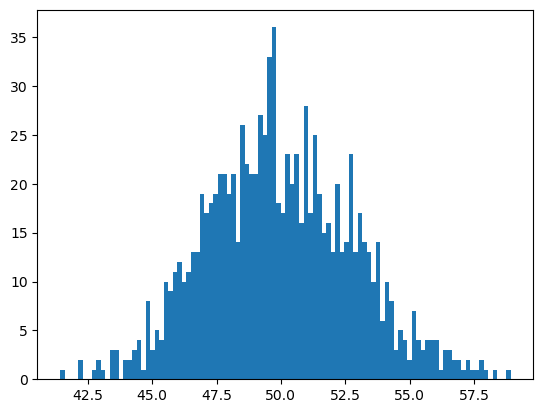

In [41]:
# импортируем библиотеки
import numpy as np
import matplotlib.pyplot as plt
 
# создаём выборку из нормального распределения
values = np.random.normal(50, 3, 1000)

# строим гистограмму
plt.hist(values, 100)
plt.show()

### Задача 9

Сгенерируйте выборку из экспоненциального распределения. Постройте несколько гистограмм со значениями ***bins = [5, 10, 20, 50, 100]***.
Подумайте и ответьте, какой фундаментальный смысл этого параметра.